In [3]:
import pandas as pd
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('cleaned_all_phones.csv')

Saving cleaned_all_phones.csv to cleaned_all_phones (1).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

In [5]:
display(df.head())

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,video_1080p,video_4K,video_8K,video_30fps,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD)
0,Y6II Compact,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,...,False,False,False,True,False,False,False,False,False,120.0
1,K20 plus,LG,Android 7.0,5.3,720x1280,2700,Li-Ion,2,2016-12-01,140.0,...,True,False,False,True,False,False,False,False,False,100.0
2,P8 Lite (2017),Huawei,Android 7.0,5.2,1080x1920,3000,Li-Ion,4,2017-01-01,147.0,...,True,False,False,True,False,False,False,False,False,420.0
3,Redmi Note 4,Xiaomi,Android 6.0,5.5,1080x1920,4100,Li-Po,4,2017-01-01,165.0,...,True,False,False,True,False,True,False,False,False,150.0
4,P10,Huawei,Android 7.0,5.1,1080x1920,3200,Li-Ion,4,2017-02-01,145.0,...,True,True,False,True,True,False,False,False,False,420.0


#Xử lí các ô xử lý dữ liệu bị khuyết + Các dòng trùng lặp

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   phone_name         1512 non-null   object 
 1   brand              1512 non-null   object 
 2   os                 1512 non-null   object 
 3   inches             1512 non-null   float64
 4   resolution         1512 non-null   object 
 5   battery            1512 non-null   int64  
 6   battery_type       1512 non-null   object 
 7   ram(GB)            1512 non-null   int64  
 8   announcement_date  1512 non-null   object 
 9   weight(g)          1512 non-null   float64
 10  storage(GB)        1512 non-null   int64  
 11  video_720p         1512 non-null   bool   
 12  video_1080p        1512 non-null   bool   
 13  video_4K           1512 non-null   bool   
 14  video_8K           1512 non-null   bool   
 15  video_30fps        1512 non-null   bool   
 16  video_60fps        1512 

In [7]:
num_dup = df.duplicated().sum()
num_nan = df.isna().sum()
print(f'Số dòng trùng lặp: {num_dup}')
print(f'Số dòng bị khuyết: {num_nan}')

Số dòng trùng lặp: 0
Số dòng bị khuyết: phone_name           0
brand                0
os                   0
inches               0
resolution           0
battery              0
battery_type         0
ram(GB)              0
announcement_date    0
weight(g)            0
storage(GB)          0
video_720p           0
video_1080p          0
video_4K             0
video_8K             0
video_30fps          0
video_60fps          0
video_120fps         0
video_240fps         0
video_480fps         0
video_960fps         0
price(USD)           0
dtype: int64


In [8]:
df[df.duplicated(keep=False)]

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,video_1080p,video_4K,video_8K,video_30fps,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD)


Không có trùng lặp giữa các dòng và không có ô nào khuyết thiếu.

In [9]:
df.drop(columns=['phone_name'], inplace=True)
df.head(1)

,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),storage(GB),...,video_1080p,video_4K,video_8K,video_30fps,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD)
0,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,16,...,False,False,False,True,False,False,False,False,False,120.0


Cột 'resolution' đang ở dạng (wxh) nên tách riêng thành width - height.

Các cột về camera ('video_...') nên chuyển về dạng 0-1 tương ứng FALSE - TRUE

Từ cột 'announcement_date' tạo cột 'announcement_year' do các thiết bị điện tử thường quan tâm đến năm ra mắt hơn là ngày tháng chi tiết

In [10]:
#Tách 'ressolution' rồi xóa
df[['width', 'height']] = df['resolution'].str.lower().str.strip().str.split('x', expand=True).astype(int)
df.drop(columns=['resolution'], inplace=True)

In [11]:
# Chuyển 'announcement_date' về dạng datetime
df['announcement_date'] = pd.to_datetime(df['announcement_date'], errors='coerce')

# Tạo cột 'announcement_year'
df['announcement_year'] = df['announcement_date'].dt.year

#Xóa 'announcement_date'
df.drop(columns=['announcement_date'], inplace=True)

In [12]:
df.head(1)

,brand,os,inches,battery,battery_type,ram(GB),weight(g),storage(GB),video_720p,video_1080p,...,video_30fps,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD),width,height,announcement_year
0,Huawei,Android 5.1,5.0,2200,Li-Po,2,140.0,16,True,False,...,True,False,False,False,False,False,120.0,720,1280,2016


#Xử lí outlier

Outlier biến số theo IQR

In [13]:
# Biến số
num_cols = ['inches', 'battery', 'ram(GB)', 'weight(g)', 'storage(GB)', 'price(USD)']
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Lọc các dòng không phải là outlier
    df = df[(df[col] >= lower) & (df[col] <= upper)]

df.shape[0]

1086

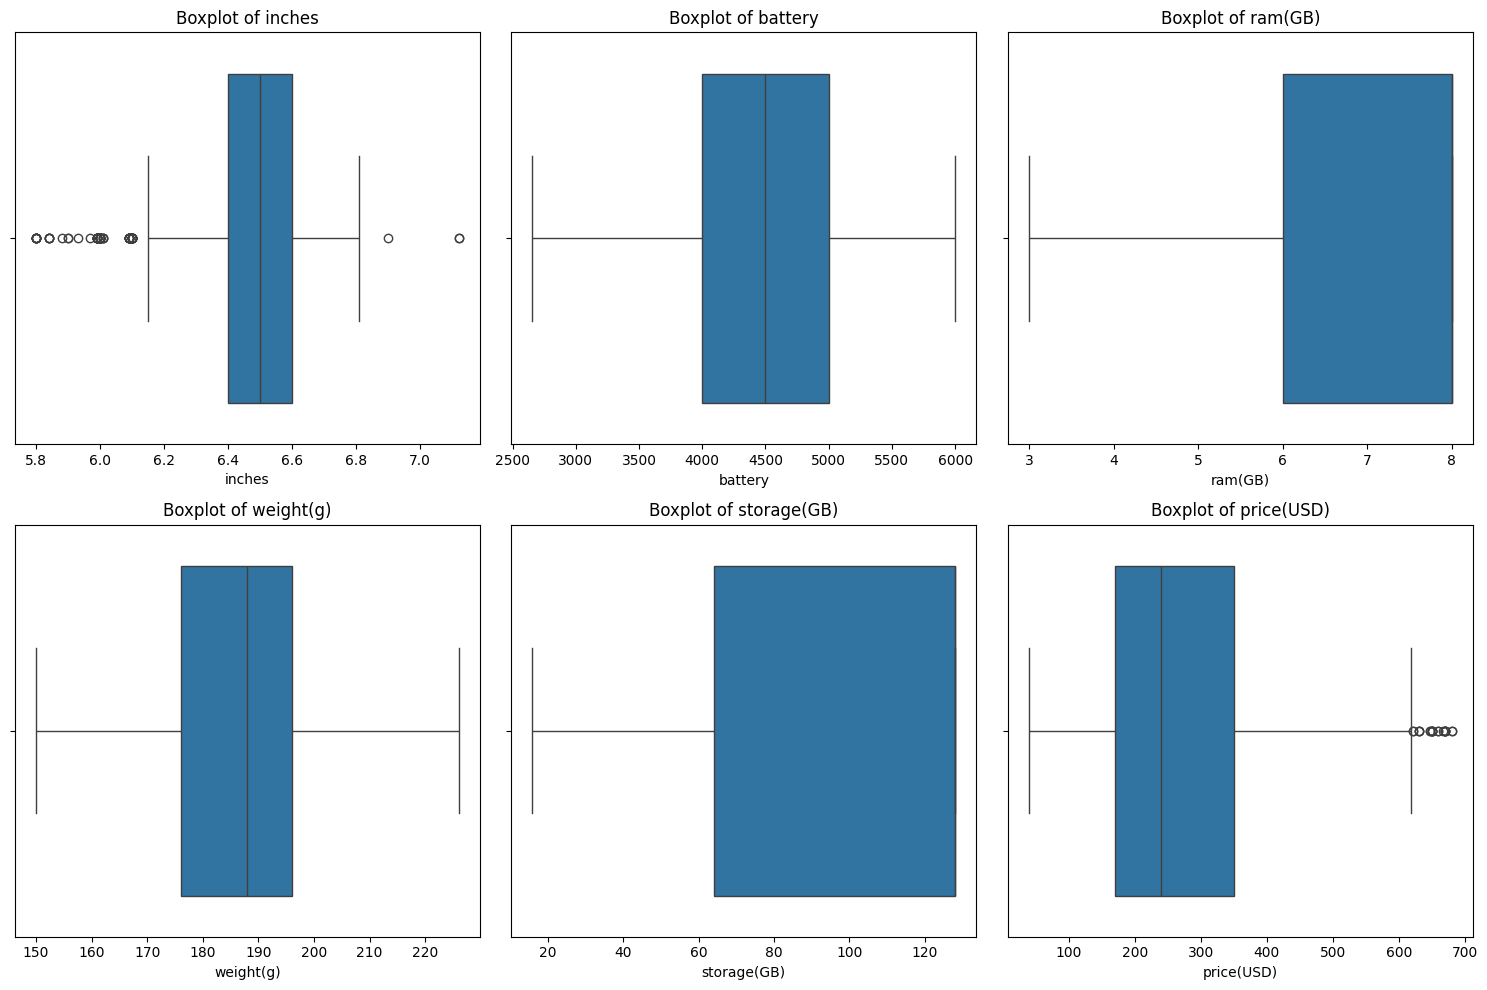

In [14]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

#Encode dữ liệu

Các biến phân loại encode bằng Label Encoder

In [15]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = ['brand', 'os', 'battery_type']
label_encoders = {}  # Lưu các encoder cho từng cột
label_mappings = {}  # Lưu bảng ánh xạ nhãn

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    label_mappings[col] = dict(zip(le.classes_, le.transform(le.classes_)))


In [16]:
for col in categorical_cols:
    print(f"\nMapping cho cột '{col}':")
    for k, v in label_mappings[col].items():
        print(f"  {k} → {v}")


Mapping cho cột 'brand':
  Apple → 0
  Google → 1
  Honor → 2
  Huawei → 3
  LG → 4
  Lenovo → 5
  OnePlus → 6
  Oppo → 7
  Realme → 8
  Samsung → 9
  Sony → 10
  Vivo → 11
  Xiaomi → 12

Mapping cho cột 'os':
  Android → 0
  Android 10 → 1
  Android 10/ Android 11 → 2
  Android 11 → 3
  Android 12 → 4
  Android 12 or 13 → 5
  Android 13 → 6
  Android 6 → 7
  Android 7.0 → 8
  Android 7.1 → 9
  Android 7.1.1 → 10
  Android 7.1.2 → 11
  Android 8.0 → 12
  Android 8.1 → 13
  Android 9.0 → 14
  Android 9.0 Pie → 15
  EMUI 12 → 16
  EMUI 13 → 17
  iOS 11.1.1 → 18
  iOS 12 → 19
  iOS 13 → 20
  iOS 14.1 → 21
  iOS 15 → 22

Mapping cho cột 'battery_type':
  Li-Ion → 0
  Li-Po → 1


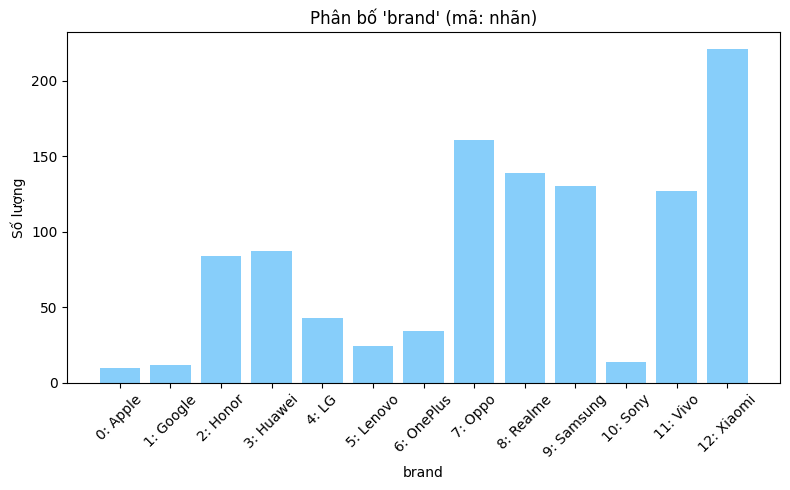

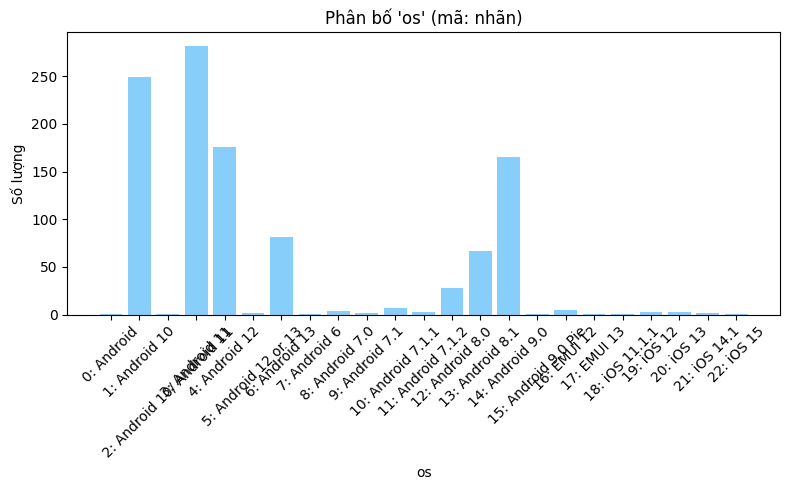

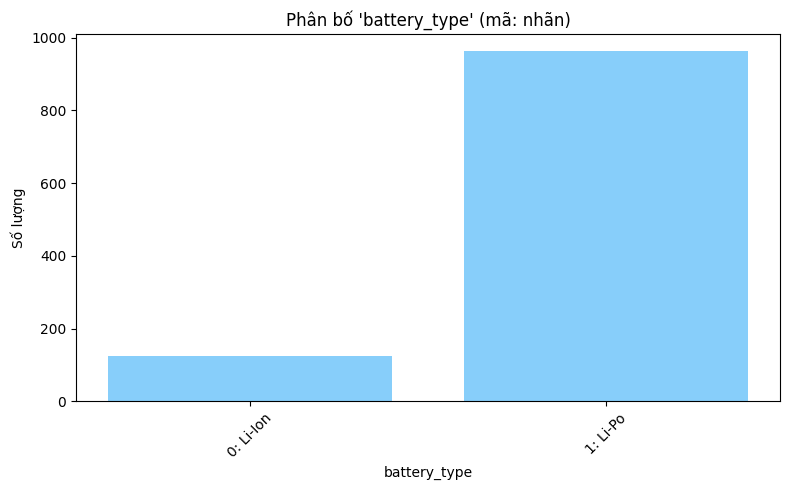

In [17]:
for col in categorical_cols:
    plt.figure(figsize=(8, 5))

    le = label_encoders[col]
    mapping = label_mappings[col]

    # Đếm số lượng theo mã đã encode
    value_counts = df[col].value_counts().sort_index()

    # Tạo label kiểu "0: Android"
    labels = [f"{v}: {k}" for k, v in sorted(mapping.items(), key=lambda x: x[1])]

    # Vẽ biểu đồ
    bars = plt.bar(range(len(value_counts)), value_counts.values, color='lightskyblue')
    plt.xticks(range(len(labels)), labels, rotation=45)

    plt.xlabel(col)
    plt.ylabel("Số lượng")
    plt.title(f"Phân bố '{col}' (mã: nhãn)")

    plt.tight_layout()
    plt.show()

Các biến bool chuyển sang int (TRUE -> 1; FALSE -> 0)

In [18]:
video_cols = [
    'video_720p', 'video_1080p', 'video_4K', 'video_8K',
    'video_30fps', 'video_60fps', 'video_120fps',
    'video_240fps', 'video_480fps', 'video_960fps'
]
df[video_cols] = df[video_cols].astype(int)

In [19]:
#Tạo thêm 1 cột tổng các chức năng camera
total_cam_func = [ i for i in df.columns if 'video' in i]
df['total_cam_func'] = df[total_cam_func].sum(axis=1)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1086 entries, 8 to 1511
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              1086 non-null   int64  
 1   os                 1086 non-null   int64  
 2   inches             1086 non-null   float64
 3   battery            1086 non-null   int64  
 4   battery_type       1086 non-null   int64  
 5   ram(GB)            1086 non-null   int64  
 6   weight(g)          1086 non-null   float64
 7   storage(GB)        1086 non-null   int64  
 8   video_720p         1086 non-null   int64  
 9   video_1080p        1086 non-null   int64  
 10  video_4K           1086 non-null   int64  
 11  video_8K           1086 non-null   int64  
 12  video_30fps        1086 non-null   int64  
 13  video_60fps        1086 non-null   int64  
 14  video_120fps       1086 non-null   int64  
 15  video_240fps       1086 non-null   int64  
 16  video_480fps       1086 non-n

In [21]:
df.head()

,brand,os,inches,battery,battery_type,ram(GB),weight(g),storage(GB),video_720p,video_1080p,...,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD),width,height,announcement_year,total_cam_func
8,10,8,6.00,2700,0,4,188.0,32,0,1,...,0,0,0,0,0,250.0,1080,1920,2017,2
15,7,7,6.00,4000,0,6,185.0,64,1,1,...,0,0,0,0,0,250.0,1080,1920,2017,4
18,9,8,6.20,3500,0,6,173.0,64,1,1,...,1,1,1,0,0,350.0,1440,2960,2017,7
29,12,10,6.44,5300,0,4,211.0,32,1,1,...,0,1,0,0,0,200.0,1080,1920,2017,5
36,7,10,6.00,4000,1,6,188.0,64,1,1,...,0,0,0,0,0,250.0,1080,1920,2017,4


#Chuẩn hóa dữ liệu

In [22]:
from sklearn.preprocessing import StandardScaler

cols_to_scale = ['inches', 'battery', 'ram(GB)', 'weight(g)', 'storage(GB)',
                 'price(USD)', 'width', 'height', 'total_cam_func']
# Tạo scaler
scaler = StandardScaler()

# Áp dụng scaler
df_scaled = df.copy()
df_scaled[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

# Xem kết quả
df_scaled.head()

,brand,os,inches,battery,battery_type,ram(GB),weight(g),storage(GB),video_720p,video_1080p,...,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD),width,height,announcement_year,total_cam_func
8,10,8,-2.328907,-2.688525,0,-1.455689,0.092204,-1.645205,0,1,...,0,0,0,0,0,-0.155144,0.376923,-0.744115,2017,-0.893852
15,7,7,-2.328907,-0.753192,0,-0.311369,-0.116843,-0.806579,1,1,...,0,0,0,0,0,-0.155144,0.376923,-0.744115,2017,0.082731
18,9,8,-1.344421,-1.497551,0,-0.311369,-0.953032,-0.806579,1,1,...,1,1,1,0,0,0.592897,2.354216,1.862446,2017,1.547605
29,12,10,-0.163038,1.182140,0,-1.455689,1.694899,-1.645205,1,1,...,0,1,0,0,0,-0.529164,0.376923,-0.744115,2017,0.571022
36,7,10,-2.328907,-0.753192,1,-0.311369,0.092204,-0.806579,1,1,...,0,0,0,0,0,-0.155144,0.376923,-0.744115,2017,0.082731


#Training model

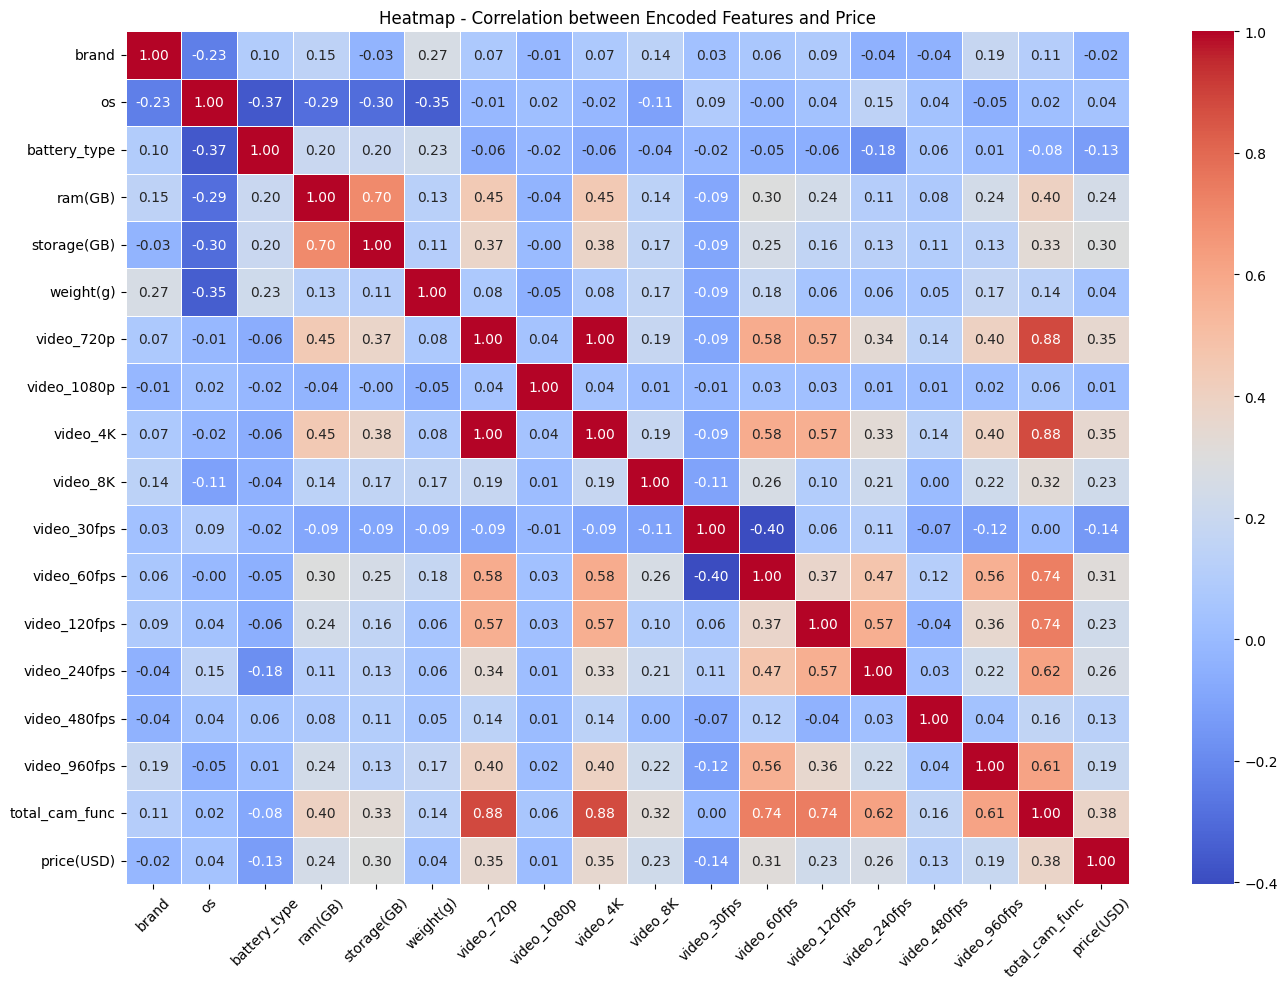

In [ ]:
# Lọc các cột cần thiết
cols = [
    'brand', 'os', 'battery_type', 'ram(GB)', 'storage(GB)', 'weight(g)',
    'video_720p', 'video_1080p', 'video_4K', 'video_8K',
    'video_30fps', 'video_60fps', 'video_120fps',
    'video_240fps', 'video_480fps', 'video_960fps',
    'total_cam_func', 'price(USD)'
]

# Tính toán ma trận tương quan
corr = df[cols].corr()

# Vẽ heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Heatmap - Correlation between Encoded Features and Price')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop(['price(USD)'], axis = 1)
y = df['price(USD)']

In [ ]:
xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(random_state=42)
rf.fit(xtrain, ytrain)
rf_pred = rf.predict(xtest)
mean_absolute_error(ytest, rf_pred)

77.03026415832599

#Testing

In [ ]:
# Các label encoder đã fit từ trước
brand_le = LabelEncoder().fit(df['brand'])
os_le = LabelEncoder().fit(df['os'])
battery_type_le = LabelEncoder().fit(df['battery_type'])

# Các cột video
video_cols = [
    'video_720p', 'video_1080p', 'video_4K', 'video_8K',
    'video_30fps', 'video_60fps', 'video_120fps',
    'video_240fps', 'video_480fps', 'video_960fps'
]

In [ ]:
def predict_phone_price(model, input_dict):
    import pandas as pd
    from sklearn.preprocessing import LabelEncoder # Import LabelEncoder

    # 1. Tạo DataFrame từ input
    temp = pd.DataFrame([input_dict])

    # 2. Tách width và height từ resolution
    temp[['width', 'height']] = temp['resolution'].str.split('x', expand=True).astype(int)

    # 3. Tạo announcement_year
    temp['announcement_year'] = pd.to_datetime(temp['announcement_date']).dt.year

    # 4. Encode các cột phân loại
    # Handle unseen brands by adding them to the encoder's classes
    if input_dict['brand'] not in brand_le.classes_:
        brand_le.classes_ = np.append(brand_le.classes_, input_dict['brand'])
    temp['brand'] = brand_le.transform(temp['brand'])

    # Similar handling for 'os' and 'battery_type'
    if input_dict['os'] not in os_le.classes_:
        os_le.classes_ = np.append(os_le.classes_, input_dict['os'])
    temp['os'] = os_le.transform(temp['os'])

    if input_dict['battery_type'] not in battery_type_le.classes_:
        battery_type_le.classes_ = np.append(battery_type_le.classes_, input_dict['battery_type'])
    temp['battery_type'] = battery_type_le.transform(temp['battery_type'])

    # 5. Chuyển video features thành int
    for col in video_cols:
        temp[col] = temp[col].astype(int)

    # 6. Tính tổng chức năng camera
    temp['total_cam_func'] = temp[video_cols].sum(axis=1)

    # 7. Xoá các cột không dùng
    temp.drop(['phone_name', 'announcement_date', 'resolution'], axis=1, inplace=True)

    # 8. Sắp xếp lại cột đúng thứ tự như X_train
    temp = temp[xtrain.columns]

    # 9. Dự đoán
    prediction = model.predict(temp)[0]
    return round(prediction, 2)

In [ ]:
new_phone = {
    'phone_name': 'Xiaomi Redmi 9',
    'brand': 'Xiaomi',
    'os': 'Android 10',
    'inches': 6.53,
    'resolution': '1080x2340',
    'battery': 5020,
    'battery_type': 'Li-Po',
    'ram(GB)': 4,
    'announcement_date': '2020-06-10',
    'weight(g)': 198,
    'storage(GB)': 64,  # Phiên bản 64GB, có thể thay đổi thành 128GB tùy nhu cầu
    'video_720p': True,
    'video_1080p': True,
    'video_4K': False,
    'video_8K': False,
    'video_30fps': True,
    'video_60fps': False,
    'video_120fps': False,
    'video_240fps': False,
    'video_480fps': False,
    'video_960fps': False
}

predicted_price = predict_phone_price(rf, new_phone)
print(f"Giá dự đoán: ${predicted_price}")

Giá dự đoán: $144.9
